# HW4 — Snow Hydrology and Machine Learning

CEE 306: Hydrology — Water and Climate | Spring 2026

**Name:** `Sayfullo Saidov`

## Overview

Coursework examining snow observations and machine-learning approaches for snow water equivalent and streamflow.

## Machine Learning Context

## Snow Observations

### SNOTEL Station Data

In [1]:
# import libraries
from zeep import Client
from zeep import helpers
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# set WSDL Client file to zeep.Client object
# this retrieves the contents of the WSDL file, which contains 'instructions'
# on what types of methods and parameters are available from this Web Service
client = Client('https://wcc.sc.egov.usda.gov/awdbWebService/services?WSDL')

### Station Metadata

In [2]:
# collect list of IDs for SNOTEL and SNOTEL-LITE stations?
# .service.getStations() is a method for getting the IDs for these stations in object 'client'
snotel_sites = client.service.getStations(networkCds=['SNTL', 'SNTLT'], logicalAnd=True)
#print(snotel_sites)

# remove sites from Alaska (not part of CONUS)
for s in snotel_sites:
    if s.split(":")[1] == "AK":
        snotel_sites.remove(s)

# collect site metadata for these sites
# .service.getStationMetadataMultiple is a method to collect metadata on the object 'client'
snotel_sites_metadata = client.service.getStationMetadataMultiple(snotel_sites)

# transform into Pandas DataFrame (first transform into dict)
metadata_dict = helpers.serialize_object(snotel_sites_metadata)
metadata_df = pd.DataFrame.from_dict(metadata_dict)

# truncate begin and end dates to only YYYY-MM-DD (remove time component)
metadata_df['beginDate_adj'] = metadata_df['beginDate'].apply(lambda x: x.split(" ")[0])
metadata_df['endDate_adj'] = metadata_df['endDate'].apply(lambda x: x.split(" ")[0])

metadata_df.drop(columns=['beginDate', 'endDate'], inplace=True)
metadata_df.rename(columns={'beginDate_adj': 'beginDate', 'endDate_adj': 'endDate'}, inplace=True)

# Write to .csv
metadata_df.to_csv('nrcs_snotel_site_list.csv', index=False, header=True)

### Station List

### Snow Water Equivalent Data

In [3]:
# get a zeep.client object - same as above
client = Client('https://wcc.sc.egov.usda.gov/awdbWebService/services?WSDL')

# Important parameters:
# - stationTriplets: station ID; you may be able to provide multiple in a list
# - elementCd: 'WTEQ' is the element code for Snow Water Equivalent. The 'Element Code' section of the reference
#    manual provides other data types that are available through this Web Service.
#    https://www.nrcs.usda.gov/wps/portal/wcc/home/dataAccessHelp/webService/webServiceReference/!ut/p/z1/jc9NDoIwEAXgs3CCPqCWuqxNBFIiqdCAsyFdkSaKLozn1xg2LmyY3STfmx9GbGS0-FeY_TPcF3_99BcSk5Sapy1HU576HFactTtWJkMKNnxBnUlVyQ6m1JxD7XXRN10BcwCjLXn8KbUxHwEUHz8w-l0BWWew2hre7pBDpyuIvRgFvVhB5IrHzbkRoZ5VkrwBnC-XyQ!!/?1dmy&current=true&urile=wcm%3apath%3a%2Fwcc%2Bcontent%2Fhome%2Fdata%2Baccess%2Bhelp%2Fweb%2Bservice%2Fweb%2Bservice%2Breference#elementCodes
# - ordinal: set this to 1. This pulls in the primary station information.
# - duration: set this to 'DAILY', this gives us daily data for the SNOTEL site
# - getFlags: set to true
# - beginDate, endDate: start and end dates of requested data
# - alwaysReturnDailyFeb29: this is always set to 'True' I believe, so we liekly don't need to change it

# Query and get the daily data:
instant_data = client.service.getData(duration='DAILY',stationTriplets='471:ID:SNTL', elementCd='WTEQ',
                                                ordinal=1, beginDate='2022-03-14', endDate='2022-03-15',
                                                getFlags = True)

### Formatting Retrieved Data

In [4]:
# Convert XML output to Python dictionary using zeep.helpers
instant_dict = helpers.serialize_object(instant_data[0]['values'])

# Convert from dictionary to Pandas DataFrame
instant_df = pd.DataFrame.from_dict(instant_dict)

In [5]:
instant_df

,0
0,12.8
1,13.0


### SWE Retrieval Function

In [6]:
# define a function to get SWE based on the client, begin and end date, and station triplets
def get_snotel_swe(client, user_stationTriplets, user_beginDate, user_endDate):

    # get the data using zeep and the arguements given above
    instant_data_WTEQ = client.service.getData(duration='DAILY', stationTriplets=user_stationTriplets,
                                          elementCd='WTEQ', ordinal=1, beginDate=user_beginDate,
                                          endDate=user_endDate, getFlags = True)

    # we can also do the same for 'TAVG', the average temperature
    instant_data_TAVG = client.service.getData(duration='DAILY', stationTriplets=user_stationTriplets,
                                          elementCd='TAVG', ordinal=1, beginDate=user_beginDate,
                                          endDate=user_endDate, getFlags = True)

    # as well as 'PRCP', precipitation
    instant_data_PREC = client.service.getData(duration='DAILY', stationTriplets=user_stationTriplets,
                                          elementCd='PREC', ordinal=1, beginDate=user_beginDate,
                                          endDate=user_endDate, getFlags = True)

    # convert the XML output to Python dictionary
    instant_dict_WTEQ = helpers.serialize_object(instant_data_WTEQ[0]['values'])
    instant_dict_TAVG = helpers.serialize_object(instant_data_TAVG[0]['values'])
    instant_dict_PREC = helpers.serialize_object(instant_data_PREC[0]['values'])

    # convert to Pandas DataFrame
    instant_df = pd.DataFrame.from_dict(instant_dict_WTEQ)
    instant_df['1'] = pd.Series(instant_dict_TAVG)
    instant_df['2'] = pd.Series(instant_dict_PREC)

    # rename columns
    instant_df.columns = ['SWE [in]', 'AirT [F]', 'PRCP [in]']

    # make type floats - this also changes 'None' to 'NaN'
    instant_df = instant_df.astype(float)

    # replace NaN values with interpolated values using pd.interpolate
    # linear interpolation is best
    # axis = 0 is needed so that this works over all columns
    instant_df = instant_df.interpolate(method='linear', axis=0)

    # return the dataframe
    return instant_df

### Example SWE Time Series

In [7]:
# variables to get daily data
user_beginDate = '2021-02-27'
user_endDate = '2021-03-04'
user_stationTriplets = '380:CO:SNTL' # this is in Butte, CO, which was shown in lecture

# get the desired dataframe in one function call
swe_data = get_snotel_swe(client=client, user_stationTriplets=user_stationTriplets,
                          user_beginDate=user_beginDate, user_endDate=user_endDate)

swe_data

,SWE [in],AirT [F],PRCP [in]
0,9.2,11.48,9.6
1,9.2,6.26,9.6
2,9.2,11.39,9.6
3,9.2,16.52,9.6
4,9.2,23.90,9.6
5,9.2,28.76,9.6
6,9.2,25.52,9.6


Text(0.5, 1.0, 'Precip from 2021-02-27 to 2021-03-04 at 380:CO:SNTL')

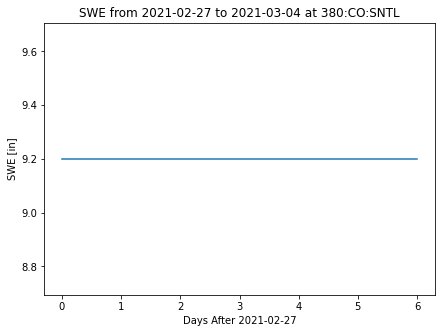

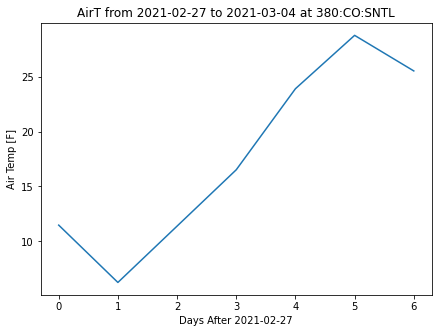

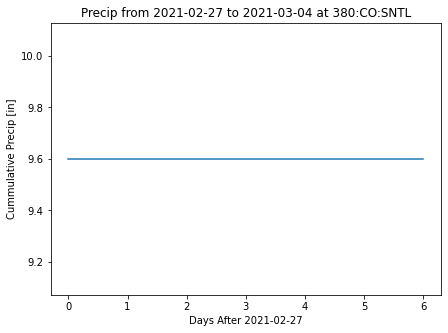

In [8]:
# plot
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(swe_data['SWE [in]'])
ax.set_ylabel('SWE [in]')
ax.set_xlabel(f'Days After {user_beginDate}')
ax.set_title(f'SWE from {user_beginDate} to {user_endDate} at {user_stationTriplets}')

fig, ax = plt.subplots(figsize=(7,5))
ax.plot(swe_data['AirT [F]'])
ax.set_ylabel('Air Temp [F]')
ax.set_xlabel(f'Days After {user_beginDate}')
ax.set_title(f'AirT from {user_beginDate} to {user_endDate} at {user_stationTriplets}')

fig, ax = plt.subplots(figsize=(7,5))
ax.plot(swe_data['PRCP [in]'])
ax.set_ylabel('Cummulative Precip [in]')
ax.set_xlabel(f'Days After {user_beginDate}')
ax.set_title(f'Precip from {user_beginDate} to {user_endDate} at {user_stationTriplets}')

## Snow Water Equivalent

In [9]:
# example: calculate density of snow from SWE

## look at a column of snow with some height (meters)
h_s = 0.5
print('The height of snow is',h_s,'m')

## melt a column of snow into liquid water and measure the height (SWE) (meters)
h_swe = 0.3
print('The height of SWE is',h_swe,'m')

## define density of water (kg / m^3)
rho_water = 1000

## compute snow density
rho_snow = h_swe*rho_water/h_s
print('The density of this snow is',rho_snow,'kg/m^3')

The height of snow is 0.5 m
The height of SWE is 0.3 m
The density of this snow is 600.0 kg/m^3


## Predicting SWE with a Convolutional Neural Network

### Libraries and Data

In [10]:
## Use air temp and SWE to train a CNN
## this uses many scripts created by RMM

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from rmm_nn import RMM_NN
from transform import float32_clamp_scaling
import utilities

DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

### Training Dataset

In [11]:
# get training data
# this will be training data
user_beginDate = '2000-10-01'
user_endDate = '2015-09-30'
user_stationTriplets = '380:CO:SNTL'
# get the desired dataframe in one function call
swe_data = get_snotel_swe(client=client, user_stationTriplets=user_stationTriplets,
                          user_beginDate=user_beginDate, user_endDate=user_endDate)


# get testing data
# this will be testing data
user_beginDate = '2015-10-01'
user_endDate = '2020-09-30'
user_stationTriplets = '380:CO:SNTL'
# get the desired dataframe in one function call
test_data = get_snotel_swe(client=client, user_stationTriplets=user_stationTriplets,
                          user_beginDate=user_beginDate, user_endDate=user_endDate)


# print length of each set
print("length of train set:",len(swe_data))
print("length of test set:",len(test_data))
print(swe_data.head())
print(test_data.head())

length of train set: 5490
length of test set: 1830
   SWE [in]  AirT [F]  PRCP [in]
0       0.0     50.72        0.0
1       0.0     51.44        0.0
2       0.0     46.94        0.0
3       0.0     37.22        0.0
4       0.0     39.92        0.3
   SWE [in]  AirT [F]  PRCP [in]
0       0.0     55.04        0.0
1       0.0     49.82        0.0
2       0.0     44.78        0.1
3       0.0     46.22        0.1
4       0.0     42.80        0.1


### Training the CNN

-- Model Definition --
-- Model Parameters --
+-----------------+------------+
|     Modules     | Parameters |
+-----------------+------------+
| layer1.0.weight |     24     |
|  layer1.0.bias  |     4      |
| layer1.2.weight |     48     |
|  layer1.2.bias  |     4      |
|   dense.weight  |  1464000   |
|    dense.bias   |    2000    |
|    out.weight   |   732000   |
|     out.bias    |    366     |
+-----------------+------------+
Total Trainable Params: 2198446

-- Model Settings --
 Channels: 2
 Epochs: 250
 Learning Rate: 0.0005



Progress:
Epoch: 249, loss: 2.737e-04
____
Training Complete
-----------------------------------
 Saving the model
-----------------------------------
 Make Predictions
-----------------------------------
 Done.
-----------------------------------
 Loss vs Epoch


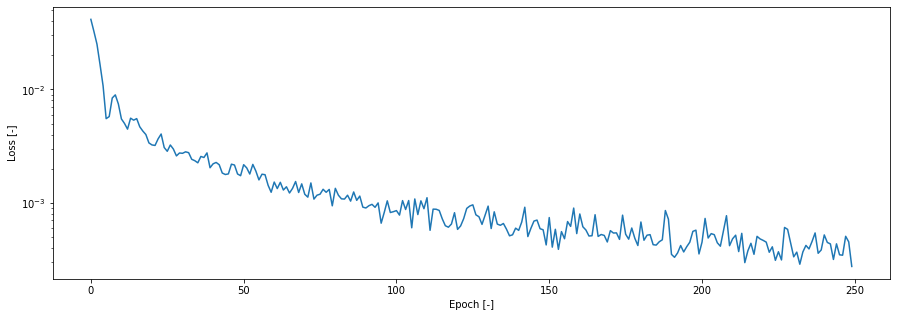

In [12]:
# define hyperparameters
N_years = 15
n_batch = N_years
nchannel = 2
n_epoch = 250
learning_rate = 5E-4
losssave=np.zeros((n_epoch,2)) # fills in loss as the model runs (using Smooth1Loss())
# N is the length of the training set
N = 366 # days in year including leap years; len(swe_data)//n_batch

#create time array in days of WY
time = np.arange(0, N)

#### set the model options ####

# grid size is going to be a 1D array days in a year (366 to pad for leap years)
model = RMM_NN(grid_size=[N], channels=nchannel)
model.to(DEVICE)
model.verbose = False # prevents every model run from printing out
model.use_dropout = True # randomly removes neurons to prevent overfitting

print("-- Model Definition --")
#print(str(summary(model, verbose=1)))
#print(model)

print("-- Model Parameters --")
utilities.count_parameters(model)

# define loss function
loss_fn = torch.nn.SmoothL1Loss()

# optimizer and solver, Adam works the best, regular SGD (stochastic gradient descent) seems to work the poorest
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)


#### NORMALIZE the data to get variables scaled from 0-1 (for P SWE) and -1 to 1 for T ####
## gives equal weights to variables so none are favored

# first get maxima for SWE and PRCP in the training set
swe_max = np.max(swe_data['SWE [in]'])
precip_max = np.max(swe_data['PRCP [in]'])

# also, max and min for temp, since air temp (F) can go below 0
temp_max = np.max(swe_data['AirT [F]'])
temp_min = np.min(swe_data['AirT [F]'])

# set up transforms
Temp_TRANSF = float32_clamp_scaling(src_range=[temp_min, temp_max], dst_range=[-1, 1])
SWE_TRANSF = float32_clamp_scaling(src_range=[0, swe_max], dst_range=[0, 1])
Precip_TRANSF = float32_clamp_scaling(src_range=[0, precip_max], dst_range=[0, 1])

# INV_SWE will be used to get usable model output
# transform normalized variables back into SWE
INV_SWE_TRANSF = float32_clamp_scaling(src_range=[0, 1], dst_range=[0, swe_max])

#### print model settings ####

print()
print("-- Model Settings --")
print(" Channels:",nchannel)
print(" Epochs:",n_epoch)
print(" Learning Rate:", learning_rate)
print()
print()



#### setup the input and output arrays ####

input_temp = np.zeros((n_batch, nchannel, N))
output_temp_temp = np.zeros((N))
output_temp = np.zeros((n_batch, N))
model_output = np.zeros(N)

#print(np.shape(np.asarray(swe_data['PRCP [in]'])))

## split the inputs (P and T) and labels (SWE) into arrays of 10 years by 366 days
#### load all the transient variables for timesteps, ie the batch members and normalize ###
# We do this so that the model is not training on 15 years as one time period, but splits up time period
# individual years. In this way, the model will recognize interannual variability
P_temp = Precip_TRANSF(np.asarray(swe_data['PRCP [in]']))
T_temp = Temp_TRANSF(np.asarray(swe_data['AirT [F]']))
SWE_temp = SWE_TRANSF(np.asarray(swe_data['SWE [in]']))
# time varying -- hitting key type error, cannot be tuple
for ii in range(0, N_years):
    i_from = ii*366
    i_to = i_from + 366
    input_temp[ii, 0, :] = P_temp[i_from:i_to]
    input_temp[ii, 1, :] = T_temp[i_from:i_to]
    output_temp[ii,:] = SWE_temp[i_from:i_to]


# convert the inputs and outputs (labels) from the temp NumPy vectors to Torch format
# convert them to floats
torch_input = torch.from_numpy(input_temp)
torch_label = torch.from_numpy(output_temp)
torch_input = torch_input.type(torch.FloatTensor).to(DEVICE)
torch_label = torch_label.type(torch.FloatTensor).to(DEVICE)



#### Train the model ####

print()
print("Progress:")
for epoch in range(n_epoch):
    optimizer.zero_grad()

    # forward pass
    batch_prediction = model(torch_input)
    loss = loss_fn(batch_prediction, torch_label)

    print("Epoch: %3d, loss: %5.3e" % (epoch, loss), end='\r')
    losssave[epoch,0] = epoch
    losssave[epoch,1] = loss
    # backward and optimize
    loss.backward()
    optimizer.step()

print()
print("____")
print("Training Complete")

#### save our progress ####

print("-----------------------------------")
print(" Saving the model")
torch.save(model, "SWE_test.pt")

# we could save the trainer as well
#trainer.save(model_path)


#### make predictions on the test data ####
print("-----------------------------------")
print(" Make Predictions")
print

# freeze the model
#### Now we want all of the neurons available so we can use the model in evaluation mode to make predictions
model.use_dropout = False
for parameter in model.parameters():
    parameter.requires_grad = False

P_test = Precip_TRANSF(np.asarray(test_data['PRCP [in]']))
T_test = Temp_TRANSF(np.asarray(test_data['AirT [F]']))
# time varying test datasets
# we now need to predict one year at a time so this should duplicate what's above
#### Predicting 5 years, one year at a time
input_test = np.zeros((5, nchannel, N))
for ii in range(0, 5):
    i_from = ii*366  #this should be a broadcast instead of a loop
    i_to = i_from + 366
    input_test[ii, 0, :] = P_test[i_from:i_to]
    input_test[ii, 1, :] = T_test[i_from:i_to]

# convert to torch format
predict_input = torch.from_numpy(input_test)

# convert to float format
predict_input = predict_input.type(torch.FloatTensor).to(DEVICE)

# makes prediction here
prediction = model(predict_input)
#print(np.shape(prediction))

# converts SWE into format we can understand
model_output = INV_SWE_TRANSF(prediction.data.cpu().numpy())
#print(np.shape(model_output))

# reshape the five years of prediction to one long array for plotting
model_plot = np.reshape(model_output,(366*5))
#print(np.shape(model_plot))

#### make predictions on the test data ####
print("-----------------------------------")
print(" Done.")


#### plot the losses ####
print("-----------------------------------")
print(" Loss vs Epoch")
fig, ax = plt.subplots(figsize=(15,5))
ax.plot(losssave[:,0], losssave[:,1])
ax.set_ylabel('Loss [-]')
ax.set_xlabel('Epoch [-]')
plt.yscale("log")
plt.show()


### Predicted and Observed SWE

In [13]:
# First, let's see the dimensions of the arrays
print(len(model_output))
print(len(model_plot))

5
1830


In [14]:
# We can also peek at the predictions
print(model_output) # each row is an individual year
model_plot # all years are combined into one long array

[[0.         0.         0.         ... 0.         0.06574421 0.09361921]
 [0.04708808 0.         0.01516013 ... 0.         0.09519335 0.2288012 ]
 [0.         0.         0.0246326  ... 0.01359239 0.04848089 0.03781268]
 [0.         0.         0.         ... 0.         0.02535265 0.15297087]
 [0.         0.         0.         ... 0.0526902  0.13528988 0.07809936]]


array([0.        , 0.        , 0.        , ..., 0.0526902 , 0.13528988,
       0.07809936], dtype=float32)

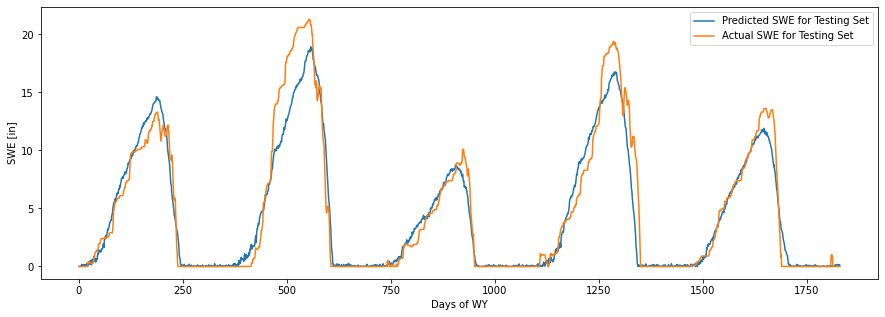

In [15]:
# Plot the predictions

fig, ax = plt.subplots(figsize=(15,5))
ax.plot(model_plot, label = 'Predicted SWE for Testing Set')
ax.plot(test_data['SWE [in]'], label = 'Actual SWE for Testing Set')
ax.set_ylabel('SWE [in]')
ax.set_xlabel('Days of WY')
ax.legend()

### Model Performance Metrics

In [16]:
!pip install permetrics #run this if the permetrics library is not yet available to you

Defaulting to user installation because normal site-packages is not writeable


In [17]:
from permetrics.regression import RegressionMetric

y_true = np.array(test_data['SWE [in]'])
y_pred = model_plot
evaluator = RegressionMetric(y_true, y_pred)
print("RMSE:")
print(evaluator.root_mean_squared_error())
print("Nash-Sutcliffe efficiency:")
print(evaluator.nash_sutcliffe_efficiency())
print("Kling-Gupta efficiency:")
print(evaluator.kling_gupta_efficiency())

RMSE:
1.5778261781901066
Nash-Sutcliffe efficiency:
0.9295066637159292
Kling-Gupta efficiency:
0.9140047670620493


## CNN Streamflow Prediction

In [18]:
def cnn_flow(n_batch, N, n_epoch, n_batch_test, learning_rate, train_data, test_data):

    n_batch = n_batch # number of sets
    N = N # length of a set
    nchannel = 2 # temp and precip
    n_epoch = n_epoch
    learning_rate = learning_rate
    time = np.arange(N)

    # Choose the ML and associated options, models are stored in ML_models.py
    # and need to be imported up top if used
    model = RMM_NN(grid_size=[N],
                   channels=nchannel)
    model.to(DEVICE)

    model.verbose=False
    model.use_dropout = True


    # loss function
    loss_fn = torch.nn.SmoothL1Loss()

    # optimizer and solver, Adam works the best, regular SGD seems to work the poorest
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)


    # Setup transforms to get variables scaled from 0-1 or -1 to 1
    # first get maxima for flow and PRCP
    flow_max = np.max(train_data['flow'])
    precip_max = np.max(train_data['precip'])

    # set up transforms
    Temp_TRANSF = float32_clamp_scaling(src_range=[np.min(train_data['temp']), np.max(train_data['temp']) ], dst_range=[-1, 1])
    Flow_TRANSF = float32_clamp_scaling(src_range=[0, flow_max], dst_range=[0, 1])
    Precip_TRANSF = float32_clamp_scaling(src_range=[0, precip_max], dst_range=[0, 1])
    # INV_FLOW will be used to get usable model output
    INV_FLOW_TRANSF = float32_clamp_scaling(src_range=[0, 1], dst_range=[0, flow_max])



    #setup the input and ouput arrays
    input_temp = np.zeros((n_batch, nchannel, N))
    output_temp_temp = np.zeros((N))
    output_temp = np.zeros((n_batch, N))
    model_output = np.zeros(N)
    # ___
    # load all the transient variables for timesteps, ie the batch members and normalize


    P_temp = Precip_TRANSF(np.asarray(train_data['precip']))
    T_temp = Temp_TRANSF(np.asarray(train_data['temp']))
    flow_temp = Flow_TRANSF(np.asarray(train_data['flow']))

    for ii in range(0, n_batch):
        i_from = ii*N  #this should be a broadcast instead of a loop
        i_to = i_from + N
        input_temp[ii, 0, :] = P_temp[i_from:i_to]
        input_temp[ii, 1, :] = T_temp[i_from:i_to]
        output_temp[ii,:] = flow_temp[i_from:i_to]



    # convert the inputs and outputs (labels) from the temp NumPy vectors to Torch format
    # convert them to Floats
    torch_input = torch.from_numpy(input_temp)
    torch_label = torch.from_numpy(output_temp)
    torch_input = torch_input.type(torch.FloatTensor).to(DEVICE)
    torch_label = torch_label.type(torch.FloatTensor).to(DEVICE)
    # ___
    # Train the model

    for epoch in range(n_epoch):
        optimizer.zero_grad()
        # Forward pass
        batch_prediction = model(torch_input)
        loss = loss_fn(batch_prediction, torch_label)


        # Backward and optimize
        loss.backward()
        optimizer.step()


    torch.save(model, "flow_test.pt")


    # freeze the model
    model.use_dropout = False
    for parameter in model.parameters():
        parameter.requires_grad = False


    # time varying test datasets
    P_temp = Precip_TRANSF(np.asarray(test_data['precip']))
    T_temp = Temp_TRANSF(np.asarray(test_data['temp']))
    # time varying test datasets
    # we now need to predict one year at a time so this should duplicate what's above
    input_temp = np.zeros((n_batch_test, nchannel, N))
    for ii in range(0, n_batch_test):
        i_from = ii*N  #this should be a broadcast instead of a loop
        i_to = i_from + N
        input_temp[ii, 0, :] = P_temp[i_from:i_to]
        input_temp[ii, 1, :] = T_temp[i_from:i_to]
    # make a prediction setting n_batch = 0 to appropriately use the test_data
    input_temp[0, 0, :] = Precip_TRANSF(np.asarray(test_data['precip'][0:N]))
    input_temp[0, 1, :] = Temp_TRANSF(np.asarray(test_data['temp'][0:N]))

    predict_input = torch.from_numpy(input_temp)

    predict_input = predict_input.type(torch.FloatTensor).to(DEVICE)
    prediction = model(predict_input)
    #print(np.shape(prediction))
    model_output = INV_FLOW_TRANSF(prediction.data.cpu().numpy())
    #print(np.shape(model_output))
    # reshape the five years of prediction to one long year
    model_plot = np.reshape(model_output,(N*n_batch_test))

    return model_plot

## Snow and Modeling Analyses

### Snow-Dominated Watersheds

`<Q1.1 Snowmelt-dominated basins show more seasonal characteristics. Most precipitations during winter months are stored as snowpack, and melts to become a flow in spring or early summer. This causes winter flows to be very low flow, but spring flows to have sudden high spikes. In contrast, basins where snowpack does not occur show more variability, where flow mostly depends on each precipitation event, not seasonal. Storm response is also immediate, where the rainfall turns into runoff or other forms.>`

`<Q1.2 Climate change's most influence is the change in the temperature. As temperature rise, most precipitation fall as rain, not as snow. This would mean there will be a decrease in snow water equivalent (SWE). So, the overall snow storage decreases during the winter period. Another effect would be the earlier arrival of precipitation into runoff/flow. It would be problematic especially during late summer when water is needed, instead of having a lot in early spring when there is no agricultural activity. Another chain reaction would be the increased risk of extreme environmental events caused by the sudden and large-scale melting of the snow. Regarding the agriculture of California, Sierra Navada mountain range will be affected the most as its natural seasonal snow storage will decrease. If most precipitation happens in winter, but agricultural demand is in summer, it would hurt the whole agricultural economy of the California and neearby states. This is due to the fact that snowpack previously served the purpose of storage of water needed later in summer, especially in Central Valley. If precipitation water is received during wrong timing, people would start relying heavily on groundwater and reservoirs, which further exacerbates the drought, which has been happening already in Colorado River Basin.>`

### Seasonal SWE and Water Management

`<Q2 Maximum SWE seems to be 26.5 inches on April 20th, and minimum is 0.0 inches starting June 20, until late autumn when the SWE start to rise once again. Peak timing (for maximum) is as I mentioned April 20th and other days in April as median peak is also located in April. Thus, the range of SWE spans from 0 to approximately 26.5 inches, with peak SWE values across years varying from near-zero in very dry years to this upper bound in wet years.`

`2012 had the lowest peak among other two (2017,2019) even during the pexpected peak month of April. 2017 and 2019 had a similar trend, with 2017 recording about 2 inches more SWE during the peak month. 2017 and 2019 both show sharper accumulation and melt transitions, while 2012 has a flattened curve mostly with relatively low SWE throughout the season. So, I would frame 2012 as a dry season while 2017 and 2019 to be higher snow/wet season.`

`These differences have most likely a direct implications for Colorado River water management. THe Colorado River Basin system depends heavily on mountain snowpack (of Rocky mountains etc) as a natural seasonal reservoir, where snow accumulated in winter is released as runoff during spring and early summer. High-SWE years like 2017 means it contributes to increased reservoir inflows, improving storage in basin for reservoirs like Lake Mead, and greater availability of water for agriculture, industry, hydropower stations, and residential use. In contrast, low-SWE years like 2012 reduce runoff dramatically, increasing the stress of drought in the basin, lowering the reservoir levels, and creating water allocation issues among states and municipalities.`


`As this graph shows the values of SWE throughout the year for several years, and each year show strong variability, it seems to be hard to manage the Colorado River system. Water supply is highly sensitive and influenced by the snowpack fluctuations and must be somehow managed to allocate proper amounts for each stakeholder.`

### Model Overfitting and Underfitting

length of train set: 366
length of test set: 366
-- Model Parameters --
+-----------------+------------+
|     Modules     | Parameters |
+-----------------+------------+
| layer1.0.weight |     24     |
|  layer1.0.bias  |     4      |
| layer1.2.weight |     48     |
|  layer1.2.bias  |     4      |
|   dense.weight  |  1464000   |
|    dense.bias   |    2000    |
|    out.weight   |   732000   |
|     out.bias    |    366     |
+-----------------+------------+
Total Trainable Params: 2198446

-- Model Settings --
 Channels: 2
 Epochs: 250
 Learning Rate: 0.0005


(1, 2, 366)

Progress:
Epoch: 249, loss: 2.317e-03
____
Training Complete
-----------------------------------
 Saving the model
-----------------------------------
 Make Predictions


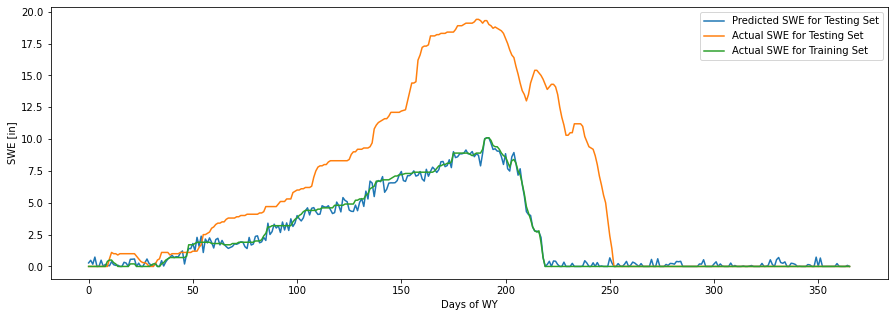

In [19]:
### code for Q3.1 here ###

WY_start = 2018


# get training data
# this will be training data
user_beginDate = f'{WY_start-1}-10-01'
user_endDate = f'{WY_start}-09-30'
user_stationTriplets = '380:CO:SNTL'
# get the desired dataframe in one function call
swe_data = get_snotel_swe(client=client, user_stationTriplets=user_stationTriplets,
                          user_beginDate=user_beginDate, user_endDate=user_endDate)

# get testing data
# this will be testing data
user_beginDate = f'{WY_start}-10-01'
user_endDate = f'{WY_start+1}-09-30'
user_stationTriplets = '380:CO:SNTL'
# get the desired dataframe in one function call
test_data = get_snotel_swe(client=client, user_stationTriplets=user_stationTriplets,
                          user_beginDate=user_beginDate, user_endDate=user_endDate)


# print length of each set
print("length of train set:",len(swe_data))
print("length of test set:",len(test_data))
#print(swe_data.head())
#print(test_data.head())


# define hyperparameters
n_batch = 1
N_years = n_batch
nchannel = 2
n_epoch = 250
learning_rate = 5E-4

# days in year (incl leap years)
N = 366

#create time array in days of WY
time = np.arange(0, N)

#### set the model options ####

# grid size is going to be a 1D array days in a year (366 to pad for leap years)
model = RMM_NN(grid_size=[N], channels=nchannel)
model.to(DEVICE)
model.verbose = False
model.use_dropout = True


print("-- Model Parameters --")
utilities.count_parameters(model)

# define loss function and optimizer
loss_fn = torch.nn.SmoothL1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

#### transform the data to get variables scaled from 0-1 (for P SWE) and -1 to 1 for T ####
## we want the min and max to be global across all years
# first get maxima for SWE and PRCP in the training set
swe_max = np.max(swe_data['SWE [in]']) #,test_data['SWE [in]'])
precip_max = np.max(swe_data['PRCP [in]']) #,test_data['PRCP [in]'])
# also, max and min for temp, since air temp (F) can go below 0
temp_max = np.max(swe_data['AirT [F]']) #, test_data['AirT [F]'])
temp_min = np.min(swe_data['AirT [F]']) #, test_data['AirT [F]'])
# set up transforms
Temp_TRANSF = float32_clamp_scaling(src_range=[temp_min, temp_max], dst_range=[-1, 1])
SWE_TRANSF = float32_clamp_scaling(src_range=[0, swe_max], dst_range=[0, 1])
Precip_TRANSF = float32_clamp_scaling(src_range=[0, precip_max], dst_range=[0, 1])
# INV_SWE will be used to get usable model output
INV_SWE_TRANSF = float32_clamp_scaling(src_range=[0, 1], dst_range=[0, swe_max])

#### print model settings ####
print()
print("-- Model Settings --")
print(" Channels:",nchannel)
print(" Epochs:",n_epoch)
print(" Learning Rate:", learning_rate)
print()
print()

#### setup the input and output arrays ####
input_temp = np.zeros((n_batch, nchannel, N))
print(np.shape(input_temp))
output_temp_temp = np.zeros((N))
output_temp = np.zeros((n_batch, N))
model_output = np.zeros(N)

## split the inputs (P and T) and labels (SWE) into arrays of 10 years by 366 days
#### load all the transient variables for timesteps, ie the batch members and normalize ###
P_temp = Precip_TRANSF(np.asarray(swe_data['PRCP [in]']))
T_temp = Temp_TRANSF(np.asarray(swe_data['AirT [F]']))
SWE_temp = SWE_TRANSF(np.asarray(swe_data['SWE [in]']))
# time varying -- hitting key type error, cannot be tuple
for ii in range(0, N_years):
    i_from = ii*366  #this should be a broadcast instead of a loop
    i_to = i_from + 366
    input_temp[ii, 0, :] = P_temp[i_from:i_to]
    input_temp[ii, 1, :] = T_temp[i_from:i_to]
    output_temp[ii,:] = SWE_temp[i_from:i_to]

# convert the inputs and outputs (labels) from the temp NumPy vectors to Torch format, then floats
torch_input = torch.from_numpy(input_temp)
torch_label = torch.from_numpy(output_temp)
torch_input = torch_input.type(torch.FloatTensor).to(DEVICE)
torch_label = torch_label.type(torch.FloatTensor).to(DEVICE)

#### Train the model ####

print()
print("Progress:")
for epoch in range(n_epoch):
    optimizer.zero_grad()

    # forward pass
    batch_prediction = model(torch_input)
    loss = loss_fn(batch_prediction, torch_label)

    # progress
    print("Epoch: %3d, loss: %5.3e" % (epoch, loss), end='\r')
    losssave[epoch,0] = epoch
    losssave[epoch,1] = loss

    # backward and optimize
    loss.backward()
    optimizer.step()

print()
print("____")
print("Training Complete")

#### save our progress ####
print("-----------------------------------")
print(" Saving the model")
torch.save(model, "SWE_test.pt")


#### make predictions ####
print("-----------------------------------")
print(" Make Predictions")
print

# freeze the model
model.use_dropout = False
for parameter in model.parameters():
    parameter.requires_grad = False

P_temp = Precip_TRANSF(np.asarray(test_data['PRCP [in]']))
T_temp = Temp_TRANSF(np.asarray(test_data['AirT [F]']))
# time varying test datasets
# we now need to predict one year at a time so this should duplicate what's above
input_temp = np.zeros((1, nchannel, N))
for ii in range(0, 1):
    i_from = ii*366  #this should be a broadcast instead of a loop
    i_to = i_from + 366
    input_temp[ii, 0, :] = P_temp[i_from:i_to]
    input_temp[ii, 1, :] = T_temp[i_from:i_to]

predict_input = torch.from_numpy(input_temp)
predict_input = predict_input.type(torch.FloatTensor).to(DEVICE)
prediction = model(predict_input)
model_output = INV_SWE_TRANSF(prediction.data.cpu().numpy())


# reshape for one year of data
model_plot = np.reshape(model_output,(366))


fig, ax = plt.subplots(figsize=(15,5))
ax.plot(model_plot, label = 'Predicted SWE for Testing Set')
ax.plot(test_data['SWE [in]'], label = 'Actual SWE for Testing Set')
ax.plot(swe_data['SWE [in]'], label = 'Actual SWE for Training Set')
ax.set_ylabel('SWE [in]')
ax.set_xlabel('Days of WY')
ax.legend()



`<Q3.1 For WY 2017 training and WY 2018 testing, I believe the model is overfitting. The training set consists of only one water year (366 daily samples) of 2017, even though the model contains approximately 2.2 million trainable parameters. So, I think that this imbalance could cause the model to just memorize the 2017 SWE pattern fully rather than learning generalizable relationship between precip., temp., and the final SWE. The training loss value was about 8.5 * 10^-4, meaning excellent fit to the training year as I could see on the graph where Predicted SWE for Testing Set matches nearly perfectly with Actual SWE for Training Set, but the Actual SWE for Testing Set (2018) is far below other two graphs. So, simply model is not learning the connections and correlations between different water years. As a result, when it is applied to 2018 with different characteristics as we saw how they chage yearly due to ongoing climate change, model seems to perform poorly.>`

`<Q3.2 For WY 2018 training and WY 2019 testing, the model seems to again show overfitting as I see it on the plotted graphs. The training set consists again of one water year. There are 2.2 million trainable parameters, while it is trained for 366 days. So, this imbalance allows model to just memorize instead of deducing proper conclusion between precip., temp., and the SWE.`

`The training loss of 6.24 * 10 ^ -4 is very low, and indicates the strong performance only on the training year. As I see on the plots, Training set and Predicted SWE for Testing Set are matching, while actual SWE for Testing Set are far above both graphs. The goal was obviously matching predicted SWE for testing set with Actual SWE for testing set, but it is not achieved. The fact that model is overlapping the training set means that it relies on a single hydrologic realization, not capturing variability of snow & environmental behavior across different years. Thus, again it is a clear case of overfitting where matching training but failing in testing.`

`<Q3.3 The solution is indicated in the previous example where it was trained on 15 years of data. Also the fact that AWS plots can show from 2026 upto 1981 for Butte demonstrates that there is a potential to use more data. To address the overfitting seen in Q3.1 and Q3.2, the main improvement is to most likely increase the amount and diversity of training data. Training on only one water year (like 2017 or 2018) is not enough because SWE, snowpack behavior varies strongly between years due to differences in snowfall, temperature, and melt timing caused by various causes like anthropogenic activities, natural events, or climate change. A better method would be to train the model on multiple years (for example 10–20 water years like from 1981-2000) so it learns general correlations between precipitation, temperature, and snow accumulation instead of just memorizing a single WY seasonal pattern. Other ways to improve might be higher dropout rate (in code, stated as model.use_dropout = True), simplifying the model (but ensuring that it does not cause underfitting where model starts mismatch with even training data) with fewer parameters or smaller layers, but always checking it and validating it with RMSE or NSE across different scenarios. Comparison of different combinations of hypparameters (changing learning rate, and n epoch) can improve the model.`


### Streamflow Prediction Experiments

In [49]:
# don't change anything in these cells - but make sure you understand it

train_start_date = '2014-10-01'
train_end_date = '2019-09-30'
wtrain_end_date = '2019-10-01' #just used for the weather training data

test_start_date = '2019-10-01'
test_end_date = '2020-09-30'

site_no = "402512074414301"

#### import data ####

# weather data for training set
url = "https://daymet.ornl.gov/single-pixel/send/saveData?lat=40.3573&lon=-74.6672&start="+train_start_date+"&end="+wtrain_end_date+"&format=csv"
weather = pd.read_csv(url, skiprows=6)
#print(url)
# calculate average temperature
weather['temp'] = (weather['tmax (deg c)'] + weather['tmin (deg c)'])/2
weather['precip'] = weather['prcp (mm/day)']
# print(weather.shape)
# streamflow data for training set
url = "https://nwis.waterdata.usgs.gov/nj/nwis/uv/?cb_00060=on&format=rdb&site_no=01401000&period=&begin_date="+train_start_date+"&end_date="+train_end_date
StonyBrook = pd.read_csv(url, sep='\t', skiprows=25)
StonyBrook.columns = ['agency','site','datetime','time_zone','flow','id']
# convert 15-min data to daily average
StonyBrook['datetime'] = pd.to_datetime(StonyBrook['datetime'])
StonyBrook_daily = StonyBrook.set_index('datetime')['flow'].resample('D').mean().reset_index()
# print(StonyBrook_daily.shape)
# combine to create training data
# combine to create training data
train_data = pd.DataFrame({
    'temp': weather['temp'].values,
    'precip': weather['precip'].values,
    'flow': StonyBrook_daily['flow'].values
})
train_data = train_data.dropna().reset_index(drop=True)

# weather data for testing set
url = "https://daymet.ornl.gov/single-pixel/send/saveData?lat=40.3573&lon=-74.6672&start="+test_start_date+"&end="+test_end_date+"&format=csv"
#print(url)
weather = pd.read_csv(url, skiprows=6)

# calculate average temperature
weather['temp'] = (weather['tmax (deg c)'] + weather['tmin (deg c)'])/2
weather['precip'] = weather['prcp (mm/day)']


# streamflow data for training set
url = "https://nwis.waterdata.usgs.gov/nj/nwis/uv/?cb_00060=on&format=rdb&site_no=01401000&period=&begin_date="+test_start_date+"&end_date="+test_end_date
StonyBrook = pd.read_csv(url, sep='\t', skiprows=25)
StonyBrook.columns = ['agency','site','datetime','time zone','flow','id']
#print(url)
# convert 15-min data to daily average
StonyBrook['datetime'] = pd.to_datetime(StonyBrook['datetime'])
StonyBrook_daily = StonyBrook.set_index('datetime')['flow'].resample('D').mean().reset_index()

#print(StonyBrook.head())

# combine to create test data
# combine to create test data
test_data = pd.DataFrame({
    'temp': weather['temp'].values,
    'precip': weather['precip'].values,
    'flow': StonyBrook_daily['flow'].values
})
test_data = test_data.dropna().reset_index(drop=True)

# print the head of the data
# print(train_data.head())
# print(test_data.head())

In [68]:
# for a N day forecast
### experiment whether N makes a difference ###
N = 3

# each batch is a N-day period
n_batch = int(len(train_data)/N)
n_batch_test = int(len(test_data)/N)

# again, two channels because two features: precipitation and temperature
nchannel = 2

# other hyperparameters to tune:
### experiment with these parameters ###
n_epoch = 100
learning_rate = 1E-3

#  cnn_flow(n_batch, N, n_epoch, n_batch_test, learning_rate, train_data, test_data):
## this returns an array which you can plot. You don't even need an x-axis array, you can call ax.plot(model_output)
model_output = cnn_flow(n_batch, N, n_epoch, n_batch_test, learning_rate, train_data, test_data)

# to save multiple runs of model output, call cnn_flow again and assign it to a new variable, i.e. model_output_2

RMSE:
96.698410589046
Nash-Sutcliffe efficiency:
0.015340572109694861
Kling-Gupta efficiency:
-0.2504953437450568


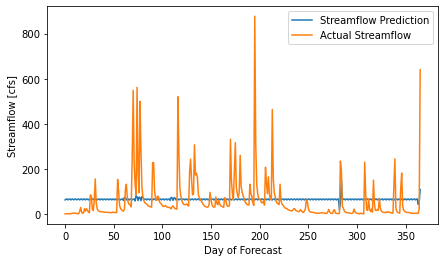

In [69]:
## plots here ##
## show multiple runs of cnn_flow with different parameters ##

# time axis for however long you want to plot
# we only add the plus one for intuitive reading of the plot below
# alternatively, just call plot(data)
time = np.arange(N)

# plot
fig,ax = plt.subplots(figsize=(7,4))
#ax.plot(time,model_output[0:N],label='Streamflow Prediction')
#ax.plot(time,test_data['flow'][0:N],label='Actual Streamflow')
ax.plot(model_output,label='Streamflow Prediction')
ax.plot(test_data['flow'],label='Actual Streamflow')
ax.set_xlabel('Day of Forecast')
ax.set_ylabel('Streamflow [cfs]')
ax.legend()

# performance metrics
#from permetrics.regression import RegressionMetric # uncomment this if you haven't imported the library
y_true = np.array(test_data['flow'])
y_pred = model_output

evaluator = RegressionMetric(y_true, y_pred)
print("RMSE:")
print(evaluator.root_mean_squared_error())
print("Nash-Sutcliffe efficiency:")
print(evaluator.nash_sutcliffe_efficiency())
print("Kling-Gupta efficiency:")
print(evaluator.kling_gupta_efficiency())


`<Q4.3 `

`For keeping hyperparameters same but having N = 366`

`RMSE: 110.45118540160541; Nash-Sutcliffe efficiency: -0.28465980082734776; Kling-Gupta efficiency: 0.16790331642366252 `

`Now for same condition, but N = 3 `

`RMSE: 96.67740961912489; Nash-Sutcliffe efficiency: 0.015768222520689545; Kling-Gupta efficiency: -0.22838220854871794`

`When N=366, the model has an acess to learn the long-term seasonal structure in the streamflow, but it tends to perform poorly as I can see from its negative NSE and high RMSE value that goes above 100. Simply, model's prediction seem to be worse than a mean flow and not capturing the watershed storage or timing precisely. Since it looks through 366 days, it can miss important event scale variability. `

`When N = 3, the model focuses only on short-term relationships between precipitation, temperature, and streamflow. This reduces the RMSE and improves NSE slightly (closer to zero). However, KG efficiency becomes negative, showing that model is failing and I can notice it from the plotted graph where model stays very low, not predicting any of the sudden spikes that happen throughout the year. So, it improves low-flow fit, but fails peak events. `

`So, for my testing case of N, 366 seemed to have a better visual result of reacting to the spikes even though the magnitude of flow and time process seemed to be still incorrect. `


`Keeping N = 366, but now testing different learning rate`

   `For 1 E-2 RMSE: 110.78955274613055; Nash-Sutcliffe efficiency: -0.29254297122177775; Kling-Gupta efficiency: 0.17643592910529504`

`For 1 E -4 RMSE: 108.95191167979998; Nash-Sutcliffe efficiency: -0.2500203454727876; Kling-Gupta efficiency: 0.18961616291062855`


`Now keeping other stuff same but changing epoch`

`25 epoch- RMSE: 113.22018688104605; Nash-Sutcliffe efficiency: -0.3498798260020013; Kling-Gupta efficiency: 0.16118952402779252`


`300 epoch - RMSE: 108.31366406068744; Nash-Sutcliffe efficiency: -0.23541783601438815; Kling-Gupta efficiency: 0.17255994582785927`


`Keeping N = 366, changing the learning rate and number of epochs show that model performance is relatively insensititve (only a bit of change) to small hyperparameter adjustments, but still consistently poor. `

`With a higher learning rate (1e-2), the model remains unstable and performs slightly worse because there was higher RMSE and more negative NSE. With a lower learning rate (1e-4), performance improves slightly but still remains weak, very similar to learning rate of 1e-3. Only difference i noticed is lowering learning rate caused more fluctations throughout the time period on the plot, but I believe it is due to training and not related to the learning rate since they are conceptually different. `

`Similarly, changing the number of epochs shows only marginal change in the result. Training for 25 epochs results in the worst performance according to the validation metrics, but the plotted graph showed that the model was now capturing the actual flow magnitude closer for small flows, even though lag was still happening. Increasing to 300 epochs slightly reduces RMSE and improves NSE but does not significantly change overall plot or the model's accuracy. In all cases, NSE value remains negative, meaning the model performs worse than simply using mean streamflow for this river.`

`So from this test of different setups, it seems that the main limitation is not optimization, but model structure and inputs. Currently, it considers only precipitation and temperature as stated in nchannel = 2. Thus, there should be the inability of precipitation and temperature alone to capture watershed storage, lagged response (which we have been doing in our forecast homework manually), and hydrologic memory. I came to this conclusion because it seems that most model setups are not capturing the actual flow's huge spike of Day 200 accurately. `


`I would add more parameters that ML model needs to consider. Firstly, I would add lagged streamflow values as there is a time between rain happening and turning into runoff that is recorded by the sensor. `

`Secondly, I would add more physically meaningful hydrologic variables, such as snow water equivalent (if it is actually contributing to the river like in Colorado River Basin), soil moisture, evapotranspiration, groundwater, and others. These directly control how much water is stored and it was proven by our comparison of linear reservoir vs. more complex model that includes Evapotranspiration and Groundwater. `


## Acknowledgement 

   `I did not use AI in coding since there was no significant change that we had to make. However, it was helpful to understand the concepts of ML better and what each line of codes' functions are in the examples. `